# Adult Census Income — experimentos com a árvore de decisão

Este notebook consolida os três experimentos conduzidos em worktrees separadas (ramos `exp/*`) e avalia a árvore final no conjunto de teste. O único classificador é o `DecisionTreeClassifier`: os experimentos variam o pré-processamento, o espaço de hiperparâmetros e a estratégia de busca. Os experimentos foram executados pelos scripts em `experimentos/` e gravaram seus resultados em `resultados/*.json` e `*.csv`; aqui esses arquivos são lidos, tabelados e comparados. Nenhuma busca de hiperparâmetros é refeita neste notebook.

**Protocolo (igual ao notebook 03).** Remoção das 24 duplicatas e dos registros com valor ausente (30.139 registros), partição estratificada 70/30 com seed 42 (21.097 / 9.042 registros) e validação cruzada estratificada de 5 folds só no treino. A seleção usa a **acurácia**, objetivo da atividade. Acurácia balanceada, precision, recall e F1 da classe `> 50 mil` e ROC-AUC são registradas lado a lado. O conjunto de teste é idêntico ao do notebook 03, o que permite comparar diretamente com a árvore inicial (85,31% de acurácia no notebook original; 85,34% quando reajustada sob o protocolo comum). Na variante que acrescenta ao treino os registros incompletos, os folds dos registros completos são os mesmos do protocolo e só os registros completos de cada fold de validação são pontuados.

| Experimento | Ramo / script | Pergunta |
| --- | --- | --- |
| 1 Pré-processamento | `exp/arvore-preprocessamento` · `exp_preprocessamento.py` | Peso amostral, escolaridade, codificação, país agrupado, capital líquido e registros incompletos mudam o resultado de duas árvores fixas? |
| 2 Estratégias clássicas | `exp/arvore` · `exp_arvore.py` | Curva de validação, busca em grade e busca aleatória encontram uma árvore melhor que a inicial, e a que custo? |
| 3 Otimização bayesiana | `exp/arvore-bayesiana` · `exp_arvore_bayesiana.py` | O TPE (Optuna) supera o amostrador aleatório com o mesmo orçamento (300 tentativas, 3 seeds)? |

Para reproduzir um experimento: `git worktree add .worktrees/arvore exp/arvore && cd .worktrees/arvore && N_JOBS=8 ../../.venv/bin/python experimentos/exp_arvore.py`.

## 1. Configuração

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, "experimentos")
import comum
from graficos import (configurar_estilo, formatar_int, formatar_pct, grafico_metricas, mostrar,
                      AZUL, AZUL_CLARO, CINZA_OUTROS, TEXTO_SEC, eixo_percentual)

configurar_estilo()
FIGURAS = Path("relatorio/figuras")
FIGURAS.mkdir(parents=True, exist_ok=True)

resultados = {n: comum.carregar_resultado(n) for n in ["preprocessamento", "arvore", "arvore_bayesiana"]}
print({n: list(r.keys()) for n, r in resultados.items()})

NOMES_METRICAS = {"acuracia": "Acurácia", "acuracia_bal": "Acurácia balanceada", "precisao": "Precision (> 50 mil)",
                  "revocacao": "Recall (> 50 mil)", "f1": "F1 (> 50 mil)", "roc_auc": "ROC-AUC"}
NOMES_EXP2 = {"grade": "busca em grade", "aleatoria": "busca aleatória"}
ROTULO_AMOSTRADOR = {"tpe": "TPE (otimização bayesiana)", "aleatoria": "Amostrador aleatório"}
ROTULO_VARIANTE = {"referencia": "referência", "com_peso_amostral": "com peso amostral", "escolaridade_texto": "escolaridade textual",
                   "escolaridade_ambas": "escolaridade textual e numérica", "codificacao_ordinal": "codificação ordinal", "pais_agrupado": "país agrupado",
                   "capital_liquido": "capital líquido", "ausentes_como_categoria": "registros incompletos no treino"}
ARVORE_INICIAL = "Árvore inicial"


def pct(x, casas=2):
    return round(float(x) * 100, casas)


df = comum.carregar_dados()
X, y = comum.separar_xy(df)
X_train, X_test, y_train, y_test = comum.dividir(X, y)
print(f"Treino: {formatar_int(len(X_train))} | Teste: {formatar_int(len(X_test))}")

# Árvore inicial (hiperparâmetros fixados a priori), ajustada no treino para a comparação pareada
arvore_inicial = comum.construir_arvore(comum.PARAMETROS_ARVORE_ANTERIOR, X_train).fit(X_train, y_train)
teste_inicial = comum.avaliar_teste(arvore_inicial, X_test, y_test)
print(f"Árvore inicial: {comum.PARAMETROS_ARVORE_ANTERIOR} | teste acurácia {pct(teste_inicial['acuracia'])}% | {comum.tamanho_arvore(arvore_inicial)}")

{'preprocessamento': ['experimento', 'descricao', 'arvores', 'n_treino_referencia', 'n_teste', 'resultados'], 'arvore': ['experimento', 'descricao', 'estrategias', 'arvore_anterior', 'curva_validacao', 'melhor_por_f1_na_grade'], 'arvore_bayesiana': ['experimento', 'descricao', 'espaco', 'n_tentativas', 'sementes', 'execucoes', 'resumo', 'curva_media']}
Treino: 21.097 | Teste: 9.042


Árvore inicial: {'max_depth': 7, 'min_samples_leaf': 10, 'min_samples_split': 20} | teste acurácia 85.34% | {'profundidade': 7, 'n_folhas': 62, 'n_nos': 123}


## 2. Experimento 1 — pré-processamento

Cada variante dos dados é avaliada com duas árvores fixas: a árvore inicial (profundidade 7, 10 registros por folha, 20 para dividir) e uma árvore de profundidade 10 (10 registros por folha). Todas usam os mesmos folds no treino e o mesmo conjunto de teste. A variante `ausentes_como_categoria` acrescenta ao treino os 2.398 registros com `Não informado`; a sua acurácia de validação é pontuada só nos registros completos (coluna `CV acurácia`), e a coluna `CV todas as linhas` mostra o valor que se obtém ao pontuar também os registros incompletos.

In [2]:
pre = pd.DataFrame(resultados["preprocessamento"]["resultados"])
tab_pre = pd.DataFrame({
    "Configuração": pre["configuracao"],
    "Modelo": pre["modelo"].str.replace("Árvore anterior", "Árvore inicial"),
    "Descrição": pre["descricao"],
    "n treino": pre["n_treino"],
    "Atributos": pre["n_atributos"],
    "Folhas": pre["n_folhas"],
    "CV acurácia (%)": (pre["cv_acuracia"] * 100).round(2),
    "CV ± (%)": (pre["cv_acuracia_std"] * 100).round(2),
    "CV todas as linhas (%)": (pre["cv_acuracia_todas_as_linhas"] * 100).round(2),
    "CV F1 (%)": (pre["cv_f1"] * 100).round(2),
    "Teste acurácia (%)": (pre["teste_acuracia"] * 100).round(2),
    "Teste F1 (%)": (pre["teste_f1"] * 100).round(2),
    "Teste ROC-AUC (%)": (pre["teste_roc_auc"] * 100).round(2),
})
display(tab_pre.drop(columns=["Descrição"]).set_index(["Modelo", "Configuração"]))
tab_pre.to_csv("relatorio/tabela_preprocessamento.csv", index=False)

,,n treino,Atributos,Folhas,CV acurácia (%),CV ± (%),CV todas as linhas (%),CV F1 (%),Teste acurácia (%),Teste F1 (%),Teste ROC-AUC (%)
Modelo,Configuração,,,,,,,,,,
Árvore inicial (prof. 7),referencia,21097,86,62,84.82,0.52,NaN,63.67,85.34,64.92,90.34
Árvore (prof. 10),referencia,21097,86,203,84.47,0.26,NaN,66.83,85.46,67.30,90.69
Árvore inicial (prof. 7),com_peso_amostral,21097,87,62,84.83,0.52,NaN,63.66,85.32,64.90,90.32
Árvore (prof. 10),com_peso_amostral,21097,87,199,84.49,0.27,NaN,66.47,85.32,66.87,90.06
Árvore inicial (prof. 7),escolaridade_texto,21097,101,58,84.40,0.49,NaN,62.95,85.48,66.10,88.91
Árvore (prof. 10),escolaridade_texto,21097,101,160,84.43,0.65,NaN,63.44,85.91,67.22,90.25
Árvore inicial (prof. 7),escolaridade_ambas,21097,102,62,84.83,0.51,NaN,63.71,85.34,64.94,90.35
Árvore (prof. 10),escolaridade_ambas,21097,102,203,84.45,0.25,NaN,66.79,85.46,67.31,90.65
Árvore inicial (prof. 7),codificacao_ordinal,21097,12,63,84.82,0.48,NaN,63.60,85.22,64.18,90.24


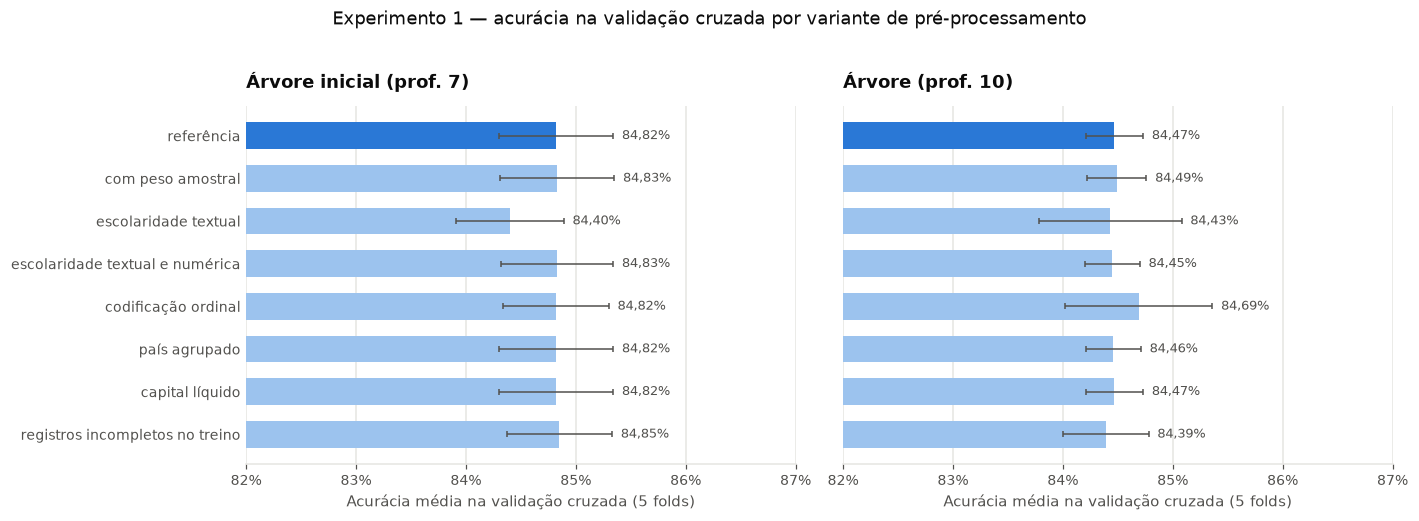

In [3]:
ARVORES_EXP1 = [a.replace("Árvore anterior", "Árvore inicial") for a in resultados["preprocessamento"]["arvores"]]
ordem_variantes = list(dict.fromkeys(tab_pre["Configuração"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, nome_arvore in zip(axes, ARVORES_EXP1):
    sub = tab_pre[tab_pre["Modelo"] == nome_arvore].set_index("Configuração").loc[ordem_variantes]
    pos = np.arange(len(sub))[::-1]
    cores = [AZUL if c == "referencia" else AZUL_CLARO for c in sub.index]
    ax.barh(pos, sub["CV acurácia (%)"], xerr=sub["CV ± (%)"], color=cores, height=0.62,
            error_kw={"ecolor": TEXTO_SEC, "capsize": 2, "elinewidth": 1})
    ax.set_yticks(pos, [ROTULO_VARIANTE.get(c, c) for c in sub.index])
    for p, v, e in zip(pos, sub["CV acurácia (%)"], sub["CV ± (%)"]):
        ax.text(v + e + 0.08, p, formatar_pct(v, 2), va="center", fontsize=8.5, color=TEXTO_SEC)
    ax.set_xlim(82, 87)
    eixo_percentual(ax, "x")
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    ax.set_title(nome_arvore)
    ax.set_xlabel("Acurácia média na validação cruzada (5 folds)")
fig.suptitle("Experimento 1 — acurácia na validação cruzada por variante de pré-processamento", y=1.02)
plt.tight_layout()
mostrar(FIGURAS / "fig_pre_arvore.png")

## 3. Experimento 2 — estratégias clássicas de busca

### 3.1 Curva de validação da profundidade

A curva repete a análise do notebook 03 para acurácia e F1, com profundidades de 1 a 30.

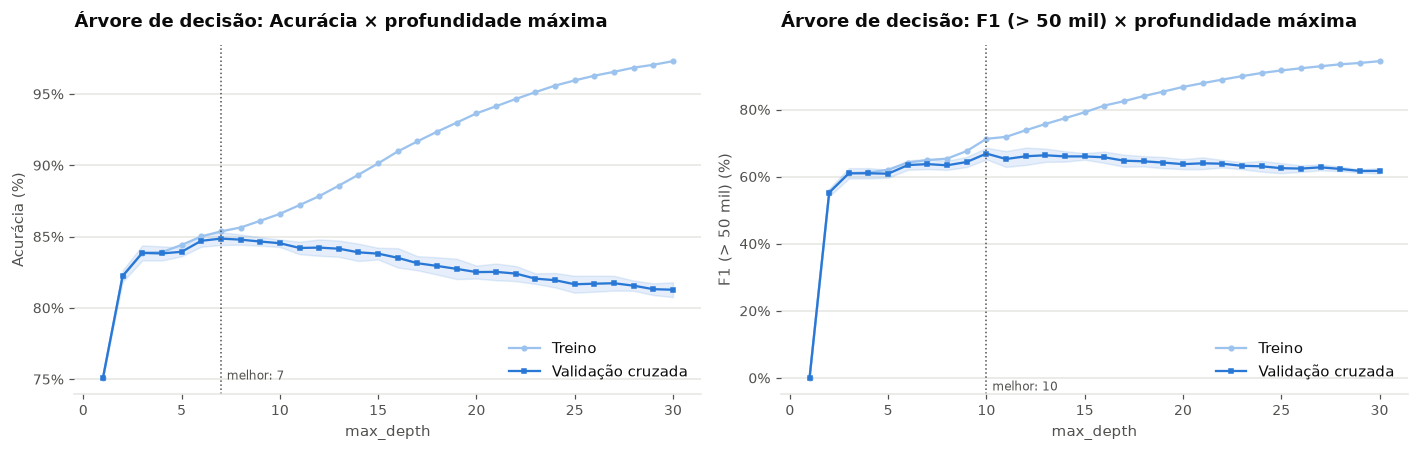

,Acurácia treino (%),Acurácia validação (%),F1 treino (%),F1 validação (%)
max_depth,,,,
1,75.10,75.10,0.00,0.00
2,82.25,82.23,55.32,55.27
3,83.87,83.86,61.05,61.00
4,83.91,83.82,61.25,61.01
5,84.41,83.94,62.07,60.89
6,85.01,84.71,64.22,63.45
7,85.37,84.86,64.95,63.75
8,85.64,84.79,65.38,63.39
9,86.11,84.66,67.64,64.38


In [4]:
arv = resultados["arvore"]
curva = pd.DataFrame(arv["curva_validacao"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (m, nome) in zip(axes, [("accuracy", "Acurácia"), ("f1", "F1 (> 50 mil)")]):
    ax.plot(curva["max_depth"], curva[f"{m}_treino"] * 100, marker="o", ms=3, color=AZUL_CLARO, label="Treino")
    ax.plot(curva["max_depth"], curva[f"{m}_validacao"] * 100, marker="s", ms=3, color=AZUL, label="Validação cruzada")
    ax.fill_between(curva["max_depth"], (curva[f"{m}_validacao"] - curva[f"{m}_validacao_std"]) * 100,
                    (curva[f"{m}_validacao"] + curva[f"{m}_validacao_std"]) * 100, color=AZUL, alpha=0.12)
    melhor = int(curva.loc[curva[f"{m}_validacao"].idxmax(), "max_depth"])
    ax.axvline(melhor, color=TEXTO_SEC, linestyle=":", linewidth=1)
    ax.text(melhor + 0.3, ax.get_ylim()[0] + 1, f"melhor: {melhor}", color=TEXTO_SEC, fontsize=8)
    ax.set_title(f"Árvore de decisão: {nome} × profundidade máxima")
    ax.set_xlabel("max_depth")
    ax.set_ylabel(f"{nome} (%)")
    ax.grid(axis="x", visible=False)
    eixo_percentual(ax, "y")
    ax.legend(loc="lower right")
plt.tight_layout()
mostrar(FIGURAS / "fig_curva_profundidade.png")

tab_curva = pd.DataFrame({
    "max_depth": curva["max_depth"],
    "Acurácia treino (%)": (curva["accuracy_treino"] * 100).round(2),
    "Acurácia validação (%)": (curva["accuracy_validacao"] * 100).round(2),
    "F1 treino (%)": (curva["f1_treino"] * 100).round(2),
    "F1 validação (%)": (curva["f1_validacao"] * 100).round(2),
}).set_index("max_depth")
display(tab_curva)

### 3.2 Busca em grade e busca aleatória

As duas buscas usam a mesma validação cruzada e selecionam pela acurácia. A grade percorre 648 combinações de cinco hiperparâmetros; a busca aleatória sorteia 300 candidatos em um espaço maior (inclui `ccp_alpha`, `max_features` e `min_impurity_decrease`). A árvore inicial é a referência.

In [5]:
linhas = []
ant = arv["arvore_anterior"]
linhas.append({"Estratégia": ARVORE_INICIAL, "Candidatos": np.nan, "Ajustes": np.nan, "Tempo (s)": np.nan,
               "Profundidade": ant["profundidade"], "Folhas": ant["n_folhas"],
               "CV acurácia (%)": pct(ant["cv"]["acuracia"]), "CV ± (%)": pct(ant["cv"]["acuracia_std"]),
               "Teste acurácia (%)": pct(ant["teste"]["acuracia"]), "Teste F1 (%)": pct(ant["teste"]["f1"]),
               "Teste ROC-AUC (%)": pct(ant["teste"]["roc_auc"]), "Melhores parâmetros": ant["parametros"]})
for e in arv["estrategias"]:
    linhas.append({"Estratégia": NOMES_EXP2[e["estrategia"]].capitalize(), "Candidatos": e["n_candidatos"],
                   "Ajustes": e["n_ajustes"], "Tempo (s)": round(e["tempo_s"], 1),
                   "Profundidade": e["profundidade"], "Folhas": e["n_folhas"],
                   "CV acurácia (%)": pct(e["cv"]["acuracia"]), "CV ± (%)": pct(e["cv"]["acuracia_std"]),
                   "Teste acurácia (%)": pct(e["teste"]["acuracia"]), "Teste F1 (%)": pct(e["teste"]["f1"]),
                   "Teste ROC-AUC (%)": pct(e["teste"]["roc_auc"]), "Melhores parâmetros": e["melhores_parametros"]})
tab_arvore = pd.DataFrame(linhas).set_index("Estratégia")
display(tab_arvore)
tab_arvore.reset_index().to_csv("relatorio/tabela_arvore.csv", index=False)
print("Melhor candidato da grade pelo F1:", arv["melhor_por_f1_na_grade"])

,Candidatos,Ajustes,Tempo (s),Profundidade,Folhas,CV acurácia (%),CV ± (%),Teste acurácia (%),Teste F1 (%),Teste ROC-AUC (%),Melhores parâmetros
Estratégia,,,,,,,,,,,
Árvore inicial,NaN,NaN,NaN,7,62,84.82,0.52,85.34,64.92,90.34,"{'max_depth': 7, 'min_samples_leaf': 10, 'min_samples_split': 20}"
Busca em grade,648.0,3240.0,41.4,20,425,85.08,0.39,85.51,68.33,90.26,"{'class_weight': None, 'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 20, 'min_samples_split': 50}"
Busca aleatória,300.0,1500.0,15.1,13,78,85.04,0.54,85.28,66.48,90.91,"{'ccp_alpha': 0.00035640256681804174, 'class_weight': None, 'criterion': 'entropy', 'max_depth': 30, 'max_features': None, 'min_impurity_decrease': 0.0001496150911574291, 'min_samples_leaf': 15, 'min_samples_split': 11}"


Melhor candidato da grade pelo F1: {'parametros': {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 50}, 'cv_acuracia': 0.8022456636587588, 'cv_f1': 0.682930367402571}


## 4. Experimento 3 — otimização bayesiana × amostrador aleatório

Os dois amostradores do Optuna (TPE e aleatório) percorrem o mesmo espaço de dez hiperparâmetros da árvore (`experimentos/otimizacao.py`), com 300 tentativas por execução e três seeds cada. A tabela mostra o melhor candidato de cada execução; o gráfico mostra a melhor acurácia de validação encontrada até cada tentativa (linhas finas: seeds; linhas grossas: média).

Tentativas  Tempo (s)  Melhor tentativa  Profundidade  Folhas  CV acurácia (%)  CV ± (%)  Teste acurácia (%)  Teste F1 (%)  \
Amostrador                 Seed                                                                                                                               
TPE (otimização bayesiana) 0            300        145               248            12      51            85.19      0.49               85.18         66.37   
                           1            300        147               206            13      51            85.27      0.47               85.43         66.85   
                           2            300        146               143            13      57            85.25      0.39               85.03         65.74   
Amostrador aleatório       0            300        133               127            10      49            84.89      0.40               85.24         64.37   
                           1            300        133               271            13      68            85.10      0.38               85.21         65.83   
                           2            300        134               143            19     101            85.10      0.22               85.47         68.31   

                                 Teste ROC-AUC (%)  
Amostrador                 Seed                     
TPE (otimização bayesiana) 0                 90.14  
                           1                 90.34  
                           2                 90.53  
Amostrador aleatório       0                 90.46  
                           1                 90.64  
                           2                 90.70

,CV média (%),CV desvio entre seeds (p.p.),CV mínimo (%),CV máximo (%),Teste média (%),Teste desvio (p.p.),Tempo médio (s)
TPE (otimização bayesiana),85.24,0.03,85.19,85.27,85.21,0.17,146.0
Amostrador aleatório,85.03,0.10,84.89,85.10,85.31,0.12,133.0


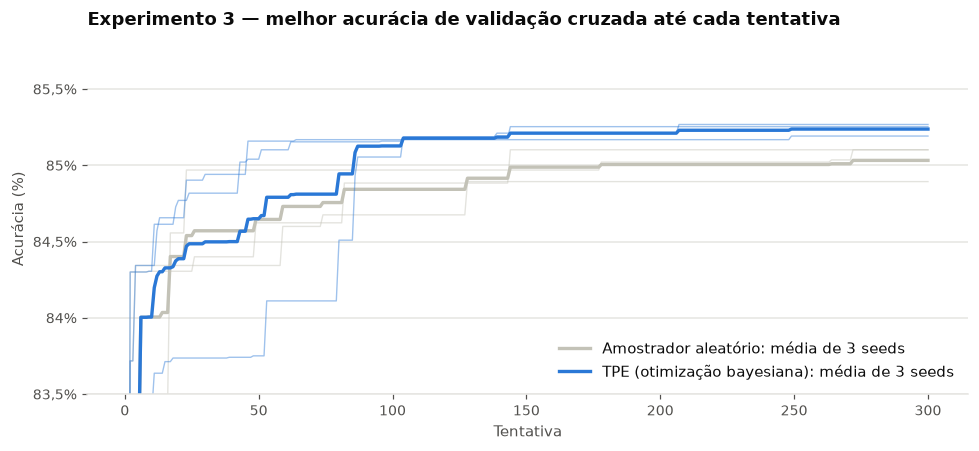

In [6]:
bay = resultados["arvore_bayesiana"]
linhas = []
for e in bay["execucoes"]:
    linhas.append({"Amostrador": ROTULO_AMOSTRADOR[e["amostrador"]], "Seed": e["semente"], "Tentativas": e["n_candidatos"],
                   "Tempo (s)": round(e["tempo_s"]), "Melhor tentativa": e["melhor_tentativa"],
                   "Profundidade": e["tamanho"]["profundidade"], "Folhas": e["tamanho"]["n_folhas"],
                   "CV acurácia (%)": pct(e["cv"]["acuracia"]), "CV ± (%)": pct(e["cv"]["acuracia_std"]),
                   "Teste acurácia (%)": pct(e["teste"]["acuracia"]), "Teste F1 (%)": pct(e["teste"]["f1"]),
                   "Teste ROC-AUC (%)": pct(e["teste"]["roc_auc"]), "Melhores parâmetros": e["melhores_parametros"]})
tab_bay = pd.DataFrame(linhas).set_index(["Amostrador", "Seed"])
display(tab_bay.drop(columns=["Melhores parâmetros"]))
tab_bay.reset_index().to_csv("relatorio/tabela_bayesiana.csv", index=False)

resumo_bay = pd.DataFrame({ROTULO_AMOSTRADOR[a]: {
    "CV média (%)": pct(r["cv_media"]), "CV desvio entre seeds (p.p.)": pct(r["cv_std"]),
    "CV mínimo (%)": pct(r["cv_min"]), "CV máximo (%)": pct(r["cv_max"]),
    "Teste média (%)": pct(r["teste_media"]), "Teste desvio (p.p.)": pct(r["teste_std"]),
    "Tempo médio (s)": round(r["tempo_medio_s"])} for a, r in bay["resumo"].items()}).T
display(resumo_bay)
resumo_bay.to_csv("relatorio/tabela_bayesiana_resumo.csv")

fig, ax = plt.subplots(figsize=(9, 4.2))
n = bay["n_tentativas"]
for a, cor in [("aleatoria", CINZA_OUTROS), ("tpe", AZUL)]:
    for e in bay["execucoes"]:
        if e["amostrador"] == a:
            ax.plot(np.arange(1, n + 1), np.array(e["melhor_ate_a_tentativa"]) * 100, color=cor, alpha=0.45, linewidth=0.9)
    ax.plot(np.arange(1, n + 1), np.array(bay["curva_media"][a]) * 100, color=cor, linewidth=2.2,
            label=f"{ROTULO_AMOSTRADOR[a]}: média de {len(bay['sementes'])} seeds")
ax.set_title("Experimento 3 — melhor acurácia de validação cruzada até cada tentativa")
ax.set_xlabel("Tentativa")
ax.set_ylabel("Acurácia (%)")
ax.set_ylim(83.5, 85.8)
ax.grid(axis="x", visible=False)
eixo_percentual(ax, "y")
ax.legend(loc="lower right")
plt.tight_layout()
mostrar(FIGURAS / "fig_bayesiana.png")

## 5. Árvore final

As árvores selecionadas nos Experimentos 2 e 3 são reunidas em uma tabela de candidatos, junto com a árvore inicial. A árvore final é o candidato de maior acurácia média na validação cruzada (a escolha não usa o conjunto de teste). Ela é reajustada no treino e avaliada uma única vez no conjunto de teste, lado a lado com a árvore inicial.

In [7]:
candidatos = {}  # nome -> dict(parametros, cv, teste, tamanho, n_candidatos, tempo_s)
candidatos[ARVORE_INICIAL] = dict(parametros=comum.PARAMETROS_ARVORE_ANTERIOR, cv=ant["cv"], teste=ant["teste"],
                                  tamanho={"profundidade": ant["profundidade"], "n_folhas": ant["n_folhas"]}, n_candidatos=np.nan, tempo_s=np.nan)
for e in arv["estrategias"]:
    candidatos[f"Exp. 2: {NOMES_EXP2[e['estrategia']]}"] = dict(
        parametros=e["melhores_parametros"], cv=e["cv"], teste=e["teste"],
        tamanho={"profundidade": e["profundidade"], "n_folhas": e["n_folhas"]}, n_candidatos=e["n_candidatos"], tempo_s=e["tempo_s"])
for e in bay["execucoes"]:
    rot = {"tpe": "TPE", "aleatoria": "amostrador aleatório"}[e["amostrador"]]
    candidatos[f"Exp. 3: {rot}, seed {e['semente']}"] = dict(
        parametros=e["melhores_parametros"], cv=e["cv"], teste=e["teste"], tamanho=e["tamanho"], n_candidatos=e["n_candidatos"], tempo_s=e["tempo_s"])

linhas = []
for nome, c in candidatos.items():
    linhas.append({"Candidato": nome, "Candidatos avaliados": c["n_candidatos"],
                   "Tempo busca (s)": round(c["tempo_s"]) if c["tempo_s"] == c["tempo_s"] else np.nan,
                   "Profundidade": c["tamanho"]["profundidade"], "Folhas": c["tamanho"]["n_folhas"],
                   "CV acurácia (%)": pct(c["cv"]["acuracia"]), "CV ± (%)": pct(c["cv"]["acuracia_std"]),
                   "CV acurácia exata": float(c["cv"]["acuracia"]),
                   "Teste acurácia (%)": pct(c["teste"]["acuracia"]), "Teste F1 (%)": pct(c["teste"]["f1"]),
                   "Teste ROC-AUC (%)": pct(c["teste"]["roc_auc"]), "Melhores parâmetros": c["parametros"]})
tab_cand = pd.DataFrame(linhas).set_index("Candidato").sort_values("CV acurácia exata", ascending=False)
display(tab_cand.drop(columns=["Melhores parâmetros", "CV acurácia exata"]))
tab_cand.reset_index().to_csv("relatorio/tabela_candidatos.csv", index=False)

nome_final = tab_cand["CV acurácia exata"].idxmax()  # seleção pelo valor exato, sem arredondamento
info_final = candidatos[nome_final]
print(f"Árvore final: {nome_final} | CV acurácia {tab_cand.loc[nome_final, 'CV acurácia (%)']}%")
print(f"Hiperparâmetros: {info_final['parametros']}")

t0 = time.perf_counter()
modelo_final = comum.construir_arvore(info_final["parametros"], X_train).fit(X_train, y_train)
tamanho_final = comum.tamanho_arvore(modelo_final)
print(f"Ajuste no treino: {time.perf_counter() - t0:.2f} s | tamanho: {tamanho_final} | árvore inicial: {comum.tamanho_arvore(arvore_inicial)}")

,Candidatos avaliados,Tempo busca (s),Profundidade,Folhas,CV acurácia (%),CV ± (%),Teste acurácia (%),Teste F1 (%),Teste ROC-AUC (%)
Candidato,,,,,,,,,
"Exp. 3: TPE, seed 1",300.0,147.0,13,51,85.27,0.47,85.43,66.85,90.34
"Exp. 3: TPE, seed 2",300.0,146.0,13,57,85.25,0.39,85.03,65.74,90.53
"Exp. 3: TPE, seed 0",300.0,145.0,12,51,85.19,0.49,85.18,66.37,90.14
"Exp. 3: amostrador aleatório, seed 2",300.0,134.0,19,101,85.10,0.22,85.47,68.31,90.70
"Exp. 3: amostrador aleatório, seed 1",300.0,133.0,13,68,85.10,0.38,85.21,65.83,90.64
Exp. 2: busca em grade,648.0,41.0,20,425,85.08,0.39,85.51,68.33,90.26
Exp. 2: busca aleatória,300.0,15.0,13,78,85.04,0.54,85.28,66.48,90.91
"Exp. 3: amostrador aleatório, seed 0",300.0,133.0,10,49,84.89,0.40,85.24,64.37,90.46
Árvore inicial,NaN,NaN,7,62,84.82,0.52,85.34,64.92,90.34


Árvore final: Exp. 3: TPE, seed 1 | CV acurácia 85.27%
Hiperparâmetros: {'criterion': 'gini', 'splitter': 'best', 'max_depth': 23, 'min_samples_leaf': 3, 'min_samples_split': 25, 'max_features': 0.8, 'ccp_alpha': 0.0002485894041712475, 'min_impurity_decrease': 2.4629728287365765e-05, 'class_weight': None}
Ajuste no treino: 0.12 s | tamanho: {'profundidade': 13, 'n_folhas': 51, 'n_nos': 101} | árvore inicial: {'profundidade': 7, 'n_folhas': 62, 'n_nos': 123}


In [8]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

teste_final = comum.avaliar_teste(modelo_final, X_test, y_test)
comparacao = pd.DataFrame({
    "Árvore inicial (%)": {NOMES_METRICAS[k]: pct(v) for k, v in teste_inicial.items()},
    "Árvore final (%)": {NOMES_METRICAS[k]: pct(v) for k, v in teste_final.items()},
})
comparacao["Diferença (p.p.)"] = pd.Series({NOMES_METRICAS[k]: round((teste_final[k] - teste_inicial[k]) * 100, 2)
                                            for k in teste_inicial})  # sobre os valores exatos, antes do arredondamento
display(comparacao)
comparacao.to_csv("relatorio/tabela_modelo_final.csv")

y_pred = modelo_final.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["≤ 50 mil", "> 50 mil"], digits=4))

,Árvore inicial (%),Árvore final (%),Diferença (p.p.)
Acurácia,85.34,85.43,0.10
Acurácia balanceada,75.03,76.59,1.56
Precision (> 50 mil),80.30,77.16,-3.14
Recall (> 50 mil),54.48,58.97,4.48
F1 (> 50 mil),64.92,66.85,1.93
ROC-AUC,90.34,90.34,-0.01


              precision    recall  f1-score   support

    ≤ 50 mil     0.8738    0.9421    0.9067      6790
    > 50 mil     0.7716    0.5897    0.6685      2252

    accuracy                         0.8543      9042
   macro avg     0.8227    0.7659    0.7876      9042
weighted avg     0.8483    0.8543    0.8474      9042



In [9]:
# Teste de McNemar (exato): os erros das duas árvores no mesmo conjunto de teste diferem?
from scipy.stats import binomtest
y_pred_inicial = arvore_inicial.predict(X_test)
acerta_final = (y_pred == y_test.values)
acerta_inicial = (y_pred_inicial == y_test.values)
b = int((acerta_final & ~acerta_inicial).sum())   # só a árvore final acerta
c = int((~acerta_final & acerta_inicial).sum())   # só a árvore inicial acerta
p_valor = binomtest(b, b + c, 0.5).pvalue
print(f"Registros em que só a árvore final acerta: {b} | só a árvore inicial acerta: {c}")
print(f"McNemar exato: p = {p_valor:.3g}")
mcnemar = {"so_final_acerta": b, "so_inicial_acerta": c, "p_valor": p_valor}

Registros em que só a árvore final acerta: 160 | só a árvore inicial acerta: 151
McNemar exato: p = 0.65


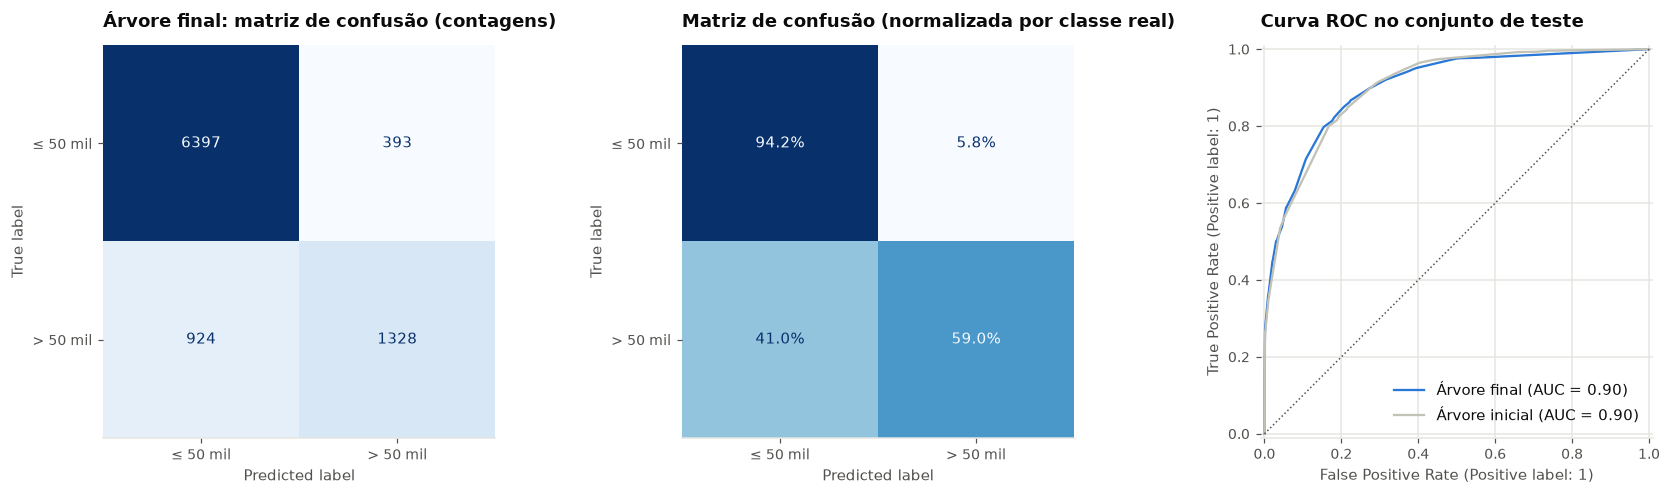

,Previsto ≤ 50 mil,Previsto > 50 mil
Real ≤ 50 mil,6397,393
Real > 50 mil,924,1328


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["≤ 50 mil", "> 50 mil"]).plot(cmap="Blues", ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title("Árvore final: matriz de confusão (contagens)")
axes[0].grid(False)
cmn = confusion_matrix(y_test, y_pred, normalize="true")
ConfusionMatrixDisplay(cmn, display_labels=["≤ 50 mil", "> 50 mil"]).plot(cmap="Blues", ax=axes[1], values_format=".1%", colorbar=False)
axes[1].set_title("Matriz de confusão (normalizada por classe real)")
axes[1].grid(False)
RocCurveDisplay.from_estimator(modelo_final, X_test, y_test, name="Árvore final", ax=axes[2], curve_kwargs={"color": AZUL})
RocCurveDisplay.from_estimator(arvore_inicial, X_test, y_test, name="Árvore inicial", ax=axes[2], curve_kwargs={"color": CINZA_OUTROS})
axes[2].plot([0, 1], [0, 1], linestyle=":", color=TEXTO_SEC, linewidth=1)
axes[2].set_title("Curva ROC no conjunto de teste")
axes[2].legend(loc="lower right")
plt.tight_layout()
mostrar(FIGURAS / "fig_modelo_final_confusao_roc.png")

tab_cm = pd.DataFrame(cm, index=pd.Index(["Real ≤ 50 mil", "Real > 50 mil"]), columns=["Previsto ≤ 50 mil", "Previsto > 50 mil"])
display(tab_cm)
cm_inicial = confusion_matrix(y_test, y_pred_inicial)

### 5.1 Importância dos atributos

A importância por permutação mede a queda de acurácia no conjunto de teste quando os valores de um atributo são embaralhados. Ela é calculada sobre as colunas originais (antes da codificação one-hot). A segunda tabela conta quantos nós da árvore final dividem por cada atributo.

2 s


,Queda de acurácia (p.p.),± (p.p.)
escolaridade_num,5.505,0.335
estado_civil,5.503,0.215
ganho_capital,4.892,0.161
idade,1.008,0.133
perda_capital,0.967,0.091
horas_semana,0.689,0.180
classe_trabalho,0.054,0.055
ocupacao,0.029,0.045
relacao_familiar,0.015,0.023
raca,0.000,0.000


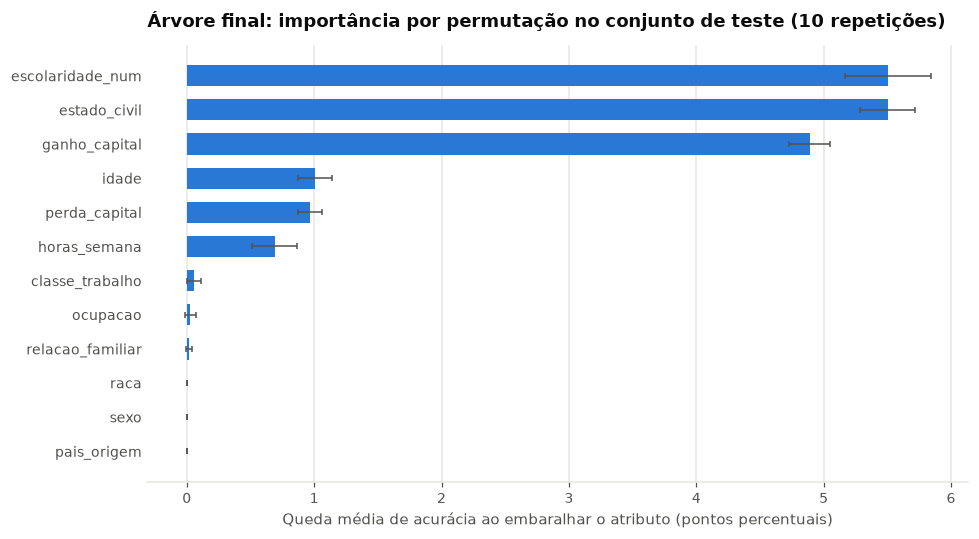

In [11]:
from sklearn.inspection import permutation_importance
t0 = time.perf_counter()
perm = permutation_importance(modelo_final, X_test, y_test, scoring="accuracy", n_repeats=10,
                              random_state=comum.SEED, n_jobs=-1)
imp = pd.DataFrame({"Queda de acurácia (p.p.)": perm.importances_mean * 100, "± (p.p.)": perm.importances_std * 100},
                   index=X_test.columns).sort_values("Queda de acurácia (p.p.)", ascending=False)
print(f"{time.perf_counter() - t0:.0f} s")
display(imp.round(3))
imp.round(3).to_csv("relatorio/tabela_importancia.csv")

fig, ax = plt.subplots(figsize=(9, 5))
ordem = imp.index[::-1]
ax.barh(ordem, imp.loc[ordem, "Queda de acurácia (p.p.)"], xerr=imp.loc[ordem, "± (p.p.)"], color=AZUL, height=0.62,
        error_kw={"ecolor": TEXTO_SEC, "capsize": 2, "elinewidth": 1})
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_title("Árvore final: importância por permutação no conjunto de teste (10 repetições)")
ax.set_xlabel("Queda média de acurácia ao embaralhar o atributo (pontos percentuais)")
plt.tight_layout()
mostrar(FIGURAS / "fig_importancia_permutacao.png")

In [12]:
# Nós de divisão por atributo original
arvore_f = modelo_final.named_steps["modelo"]
nomes_feat = np.asarray(modelo_final[:-1].get_feature_names_out())
feat = arvore_f.tree_.feature
feat = feat[feat >= 0]
originais = list(X_train.columns)
def coluna_original(nome):
    return next(c for c in sorted(originais, key=len, reverse=True) if nome == c or nome.startswith(c + "_"))
splits = pd.Series([coluna_original(n) for n in nomes_feat[feat]]).value_counts().rename("Nós de divisão").to_frame()
splits["Proporção (%)"] = (splits["Nós de divisão"] / splits["Nós de divisão"].sum() * 100).round(1)
display(splits)
splits.to_csv("relatorio/tabela_splits.csv")
print(f"Nós internos: {len(feat)} | atributos usados: {len(splits)} de {len(originais)}")

,Nós de divisão,Proporção (%)
perda_capital,12,24.0
escolaridade_num,8,16.0
horas_semana,8,16.0
idade,6,12.0
ocupacao,6,12.0
ganho_capital,4,8.0
classe_trabalho,3,6.0
estado_civil,1,2.0
sexo,1,2.0
relacao_familiar,1,2.0


Nós internos: 50 | atributos usados: 10 de 12


## 6. Persistência da árvore final

O pipeline completo (codificação + árvore) é salvo em `modelos/` (pasta ignorada pelo git), e `resultados/modelo_final.json` guarda as métricas, o teste de McNemar, a matriz de confusão, as importâncias e os nós de divisão, que alimentam a auditoria numérica do relatório (`relatorio/auditoria.py`).

In [13]:
Path("modelos").mkdir(exist_ok=True)
artefato = {
    "modelo": nome_final,
    "pipeline": modelo_final,
    "parametros": info_final["parametros"],
    "colunas_entrada": list(X_train.columns),
    "n_treino": len(X_train), "n_teste": len(X_test),
    "cv": info_final["cv"],
    "tamanho": tamanho_final,
    "tamanho_inicial": comum.tamanho_arvore(arvore_inicial),
    "teste_final": teste_final,
    "teste_inicial": teste_inicial,
    "mcnemar": mcnemar,
    "matriz_confusao": {"vn": int(cm[0, 0]), "fp": int(cm[0, 1]), "fn": int(cm[1, 0]), "vp": int(cm[1, 1])},
    "matriz_confusao_inicial": {"vn": int(cm_inicial[0, 0]), "fp": int(cm_inicial[0, 1]), "fn": int(cm_inicial[1, 0]), "vp": int(cm_inicial[1, 1])},
    "importancia": [{"atributo": a, "queda_pp": float(r["Queda de acurácia (p.p.)"]), "std_pp": float(r["± (p.p.)"])} for a, r in imp.iterrows()],
    "splits": {k: int(v) for k, v in splits["Nós de divisão"].items()},
    "n_nos_internos": int(len(feat)),
    "candidatos": {n: {"cv_acuracia": float(c["cv"]["acuracia"])} for n, c in candidatos.items()},
    "protocolo": {"seed": comum.SEED, "teste": comum.TESTE, "folds": comum.FOLDS},
}
joblib.dump(artefato, "modelos/modelo_final.joblib", compress=3)
resumo_final = {k: v for k, v in artefato.items() if k != "pipeline"}
with open("resultados/modelo_final.json", "w", encoding="utf-8") as f:
    json.dump(comum._serializavel(resumo_final), f, ensure_ascii=False, indent=2)
print("Salvo: modelos/modelo_final.joblib e resultados/modelo_final.json")

Salvo: modelos/modelo_final.joblib e resultados/modelo_final.json


## 7. Síntese

- **Pré-processamento (Exp. 1):** as oito variantes mudam a acurácia de validação da árvore inicial entre 84,40% e 84,85% e a da árvore de profundidade 10 entre 84,39% e 84,69%, faixas da ordem do desvio entre folds (0,25 a 0,67 p.p.). Peso amostral, duas colunas de escolaridade, país agrupado e capital líquido não ajudam. A codificação ordinal reduz os atributos de 86 para 12 sem perda (84,69% contra 84,47% na árvore de profundidade 10). Pontuar os registros incompletos na validação inflava a acurácia da variante `ausentes_como_categoria` em 0,5 p.p.; com a pontuação só nos registros completos, a variante fica igual à referência.
- **Estratégias clássicas (Exp. 2):** a curva de validação tem o máximo na profundidade 7 (84,86%), a da árvore inicial. Grade (648 candidatos) e busca aleatória (300) chegam a 85,08% e 85,04% na validação e 85,51% e 85,28% no teste, em 41 s e 15 s. Nenhuma supera a árvore inicial além do erro padrão do teste (cerca de 0,4 p.p.).
- **Otimização bayesiana (Exp. 3):** com 300 tentativas e o mesmo espaço, o TPE chega a 85,24% em média nas três seeds e o amostrador aleatório a 85,03%. A vantagem de 0,2 p.p. é consistente entre as seeds, mas no teste as duas estratégias ficam em 85,21% e 85,31%.
- **Árvore final:** a execução de seed 1 do TPE (85,27% em validação cruzada) obteve **85,43% de acurácia no teste** contra 85,34% da árvore inicial: +0,09 p.p., diferença que o McNemar não distingue do acaso (160 acertos exclusivos contra 151, p = 0,65). O recall da classe `> 50 mil` sobe 4,5 p.p. e a precision cai 3,1 p.p. Escolaridade, estado civil e ganho de capital são os atributos mais importantes por permutação; sexo, raça e país de origem têm efeito nulo.